In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal.windows import hamming
from scipy.signal import lfilter
from scipy.signal import freqz
from scipy.linalg import toeplitz

import os

PATH = os.getcwd()
print(f'PATH: {PATH}')

true = True
false = False

PATH: /home/andre/Documentos/git/PES_PPGEEC2320/projeto-01


# Funções auxiliares

In [2]:
def gera_sinal(As, Ap, ruido):
    n = np.arange(N)
    # ruido = np.random.normal(0, np.sqrt(sigma_c), N)
    c = lfilter([1], Ap, ruido)
    v = np.random.normal(0, np.sqrt(sigma_v), N)
    phi_s = np.random.uniform(-np.pi, np.pi)
    s = As*np.sin(omega_alvo*n + phi_s)
    return s + c + v

def levinson_durbin(r, p):
    """
    Levinson-Durbin recursivo (real ou complexo).
    r[m] = E{ x[n] x*[n-m] },  m = 0..p
    """
    r = np.asarray(r, dtype=complex)

    if p == 0:
        return np.array([1.0 + 0j]), r[0].real, np.array([], dtype=complex)

    a_ant, E_ant, k_ant = levinson_durbin(r, p - 1)

    lam = np.dot(a_ant, r[p:0:-1])
    k = -lam / E_ant

    a_ext = np.append(a_ant, 0.0)
    a = a_ext + k * np.conj(a_ext[::-1])   # conjugado aqui

    E = E_ant * (1.0 - abs(k)**2)          # |k|^2 aqui

    return a, E, np.append(k_ant, k)

def yule_walker(r, p):
    """
    Resolve as equações de Yule-Walker diretamente.

    r : autocorrelação r[0], r[1], ..., r[p]
    p : ordem do preditor

    Retorna:
      a : coeficientes [1, a1, ..., ap]
      E : erro de predição
    """
    r = np.asarray(r, dtype=complex)

    # Matriz Toeplitz Hermitiana: R[i,j] = r[i-j], com r[-m] = conj(r[m])
    R = toeplitz(r[:p], np.conj(r[:p]))

    # R @ [a1..ap] = -[r1..rp]
    coef = np.linalg.solve(R, -r[1:p + 1])
    a = np.concatenate(([1.0], coef))

    # E = soma_{j=0}^{p} a_j * conj(r[j])
    E = np.dot(a, np.conj(r[:p + 1])).real

    return a, E

# Parâmetros do problema

In [3]:
N = 16384
j = 1j

# Parâmetros do c[n]

polos_clutter = [0.92*np.exp(j*0.15*np.pi),0.92*np.exp(-j*0.15*np.pi),
                 0.85*np.exp(j*0.42*np.pi),0.85*np.exp(-j*0.42*np.pi)]

Ap_c = np.poly(polos_clutter)
sigma_c = 1

ruido = np.random.normal(0, np.sqrt(sigma_c), N)

# Parâmetros de s[n]

_, H0 = freqz([1], Ap_c, worN=[0.4*np.pi])
Pc_alvo = sigma_c * np.abs(H0[0])**2

omega_alvo = 0.4*np.pi
As = np.sqrt((2*Pc_alvo)/150)

phi_s = np.random.uniform(-np.pi, np.pi)         

#Parâmetros de v[n]
sigma_v = 0.3

# Gerando x[n]

(16384,)


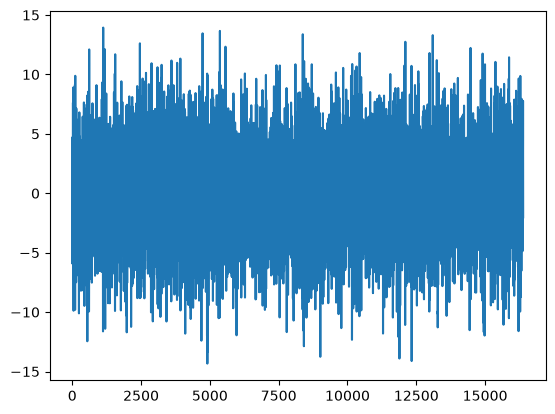

In [4]:
x = gera_sinal(As, Ap_c, ruido)

print(np.shape(x))

plt.plot(x)
plt.show()

# Tarefas

## Estimando o espectro de potência de x[n] (método de Welch)

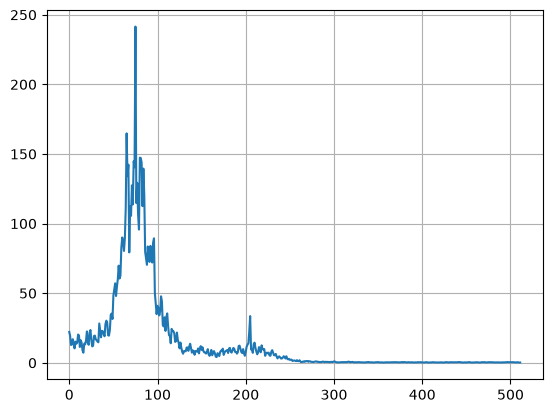

In [5]:
Nfft = 1024 # tamanho de cada bloco de fft
window = hamming(Nfft, sym=True) # janela que faz um produto ponto a ponto com cada um dos 16 blocos de x[n]. Valores variam de 0.08 a 1

# O papel do U é colocar a estimativa na mesma escala da DEP teórica.  e a curva não seria comparável com Pc. 
# Sem ele, |Xb|² sairia multiplicado por um fator que depende do tamanho do bloco e da janela (≈ σ²·U),
# Dividindo por U, o valor esperado de Pxx passa a ser a DEP verdadeira (σ² no caso de ruído branco, e a DEP do processo em geral).

U = np.sum(window**2)                 

# Número de blocos formados a partir da divisão de x[n]

nblocks = int(np.floor(N/Nfft))


Pxx = np.zeros(Nfft)

for b in range(nblocks):
    seg = x[b*Nfft:(b+1)*Nfft]
    Xb = np.fft.fft(seg * window)
    Pxx += np.abs(Xb)**2 / U

Pxx /= nblocks # mantém só os 512 primeiros bins (k = 0 a 511, de 0 a π)

w_est = 2*np.pi*np.arange(Nfft)/Nfft  # corte do eixo para ficar com o mesmo tamanho de Pxx

Pxx = Pxx[:Nfft//2]  # Reescala o eixo da potencia para a metade 0, pi  

w_est = w_est[:Nfft//2] # Reescala o eixo das frequencias para a metade 0, pi 

plt.plot(Pxx)
plt.grid()
plt.show()

## Estimando a autocorrelação $\hat{r}_x(n)$

(21,)


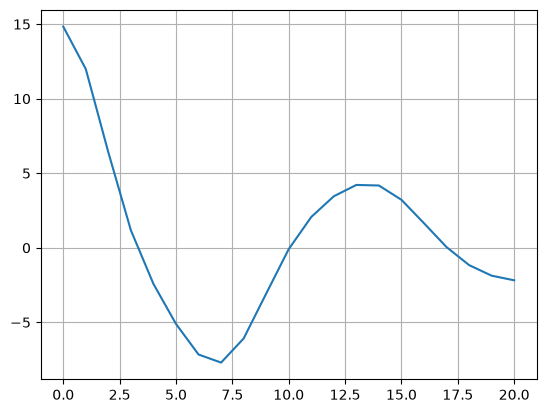

In [6]:
pmax = 10
rx_hat = np.zeros(2*pmax + 1)

for k in range(2*pmax+1):
    acc=0
    for n in range(k, N): 
        acc += x[n]*x[n-k]
    rx_hat[k] = acc / N     

print(np.shape(rx_hat))

plt.plot(rx_hat)
plt.grid()
plt.show()

## Erro do modelo 

Comparação entre os dois métodos:

1. Yule-Walker;
2. Algoritmo de Levinson-Durbin

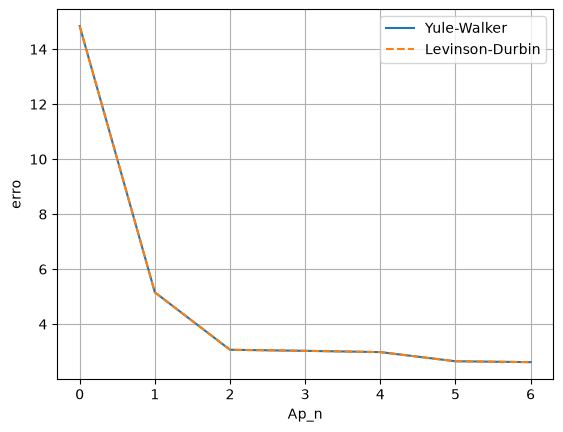

In [7]:
p_selected = 7

eyw = np.zeros(p_selected)
eld = np.zeros(p_selected)

for i in range(p_selected):
    ap, eld[i], _ = levinson_durbin(rx_hat, i)
    _, eyw[i] = yule_walker(rx_hat, i)

# Vetor temporario para ser a quantidade de polos
temp = np.arange(0,p_selected,step=1)

plt.plot(temp, eyw, label='Yule-Walker')
plt.plot(temp, eld, label='Levinson-Durbin', ls='--')
plt.ylabel('erro')
plt.xlabel(r'Ap_n')
plt.xticks(np.arange(0,p_selected,step=1))
plt.legend()
plt.grid(true)
plt.show()

del temp

Com os coeficientes $a_p(k)$ e com o último erro calculado. Em um modelo
AR(p) a função H(z) é calculada por:

$H(z) = \frac{b_0}{1+\sum_{k=1}^{p} a_p(k)z^{-k}}$

## Filtro Branqueador

In [8]:
p = p_selected                         # ordem escolhida na tarefa anterior
kidx = np.arange(p + 1, 2*p + 1)        # defasagens k = p+1, ..., 2p (nunca k = 0)

Mmod = np.zeros((p, p), dtype=rx_hat.dtype)
rhsmod = np.zeros(p, dtype=rx_hat.dtype)

for i in range(p):
    kk = kidx[i]
    for l in range(1, p + 1):
        Mmod[i, l - 1] = rx_hat[kk - l]     # r_x na defasagem kk - l
    rhsmod[i] = -rx_hat[kk]

a_hat = np.linalg.solve(Mmod, rhsmod)
a_hat_full = np.concatenate(([1.0], a_hat))  # A_p(z) = 1 + a1 z^-1 + ... + ap z^-p

e = lfilter(a_hat_full, 1, x)                # sinal branqueado

print(np.shape(e))

(16384,)


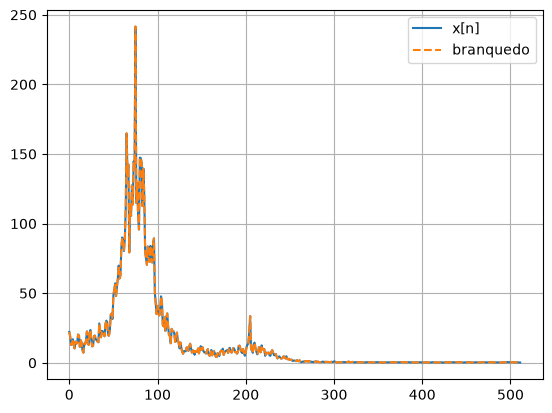

In [9]:
Nfft = 1024 # tamanho de cada bloco de fft
window = hamming(Nfft, sym=True) # janela que faz um produto ponto a ponto com cada um dos 16 blocos de x[n]. Valores variam de 0.08 a 1

# O papel do U é colocar a estimativa na mesma escala da DEP teórica.  e a curva não seria comparável com Pc. 
# Sem ele, |Xb|² sairia multiplicado por um fator que depende do tamanho do bloco e da janela (≈ σ²·U),
# Dividindo por U, o valor esperado de Pxx passa a ser a DEP verdadeira (σ² no caso de ruído branco, e a DEP do processo em geral).

U = np.sum(window**2)                 

# Número de blocos formados a partir da divisão de x[n]

nblocks = int(np.floor(N/Nfft))


Pxx_e = np.zeros(Nfft)

for b in range(nblocks):
    seg = e[b*Nfft:(b+1)*Nfft]
    Xb = np.fft.fft(seg * window)
    Pxx_e += np.abs(Xb)**2 / U

Pxx_e /= nblocks # mantém só os 512 primeiros bins (k = 0 a 511, de 0 a π)

w_est = 2*np.pi*np.arange(Nfft)/Nfft  # corte do eixo para ficar com o mesmo tamanho de Pxx

Pxx_e = Pxx[:Nfft//2]  # Reescala o eixo da potencia para a metade 0, pi  

w_est = w_est[:Nfft//2] # Reescala o eixo das frequencias para a metade 0, pi 

plt.plot(Pxx, label='x[n]')
plt.plot(Pxx_e, label='branquedo', ls='--')
plt.grid()
plt.legend()
plt.show()